✅ Successfully loaded 21 rows of clean retrieval data.
💾 High-resolution IEEE graph saved as 'fedrag_final_results.png'


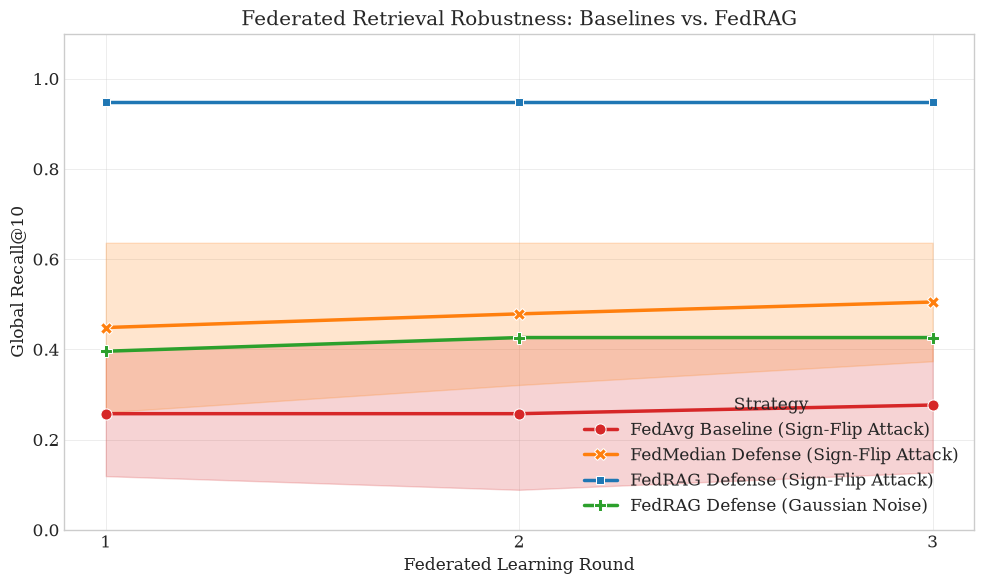

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# IEEE publication-ready formatting
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'lines.linewidth': 2.5,
    'lines.markersize': 8
})

def generate_ieee_graphs(csv_path="federated_results.csv"):
    try:
        df = pd.read_csv(csv_path)
        print(f"✅ Successfully loaded {len(df)} rows of clean retrieval data.")
    except FileNotFoundError:
        print("❌ CSV not found. Run 'run_experiments.py' first.")
        return

    # Smart mapping for the 4-experiment matrix (3 rounds per test)
    strategies = []
    for i in range(len(df)):
        block_index = i // 3
        test_type = block_index % 4

        if test_type == 0:
            strategies.append("FedAvg Baseline (Sign-Flip Attack)")
        elif test_type == 1:
            strategies.append("FedMedian Defense (Sign-Flip Attack)")
        elif test_type == 2:
            strategies.append("FedRAG Defense (Sign-Flip Attack)")
        elif test_type == 3:
            strategies.append("FedRAG Defense (Gaussian Noise)")

    df['Strategy'] = strategies

    # Create the comparative figure
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.lineplot(
        data=df,
        x='Round',
        y='Global_Recall_at_10',
        hue='Strategy',
        style='Strategy',
        markers=True,
        dashes=False,
        ax=ax,
        palette=['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c'] # Red, Orange, Blue, Green
    )

    ax.set_title("Federated Retrieval Robustness: Baselines vs. FedRAG")
    ax.set_xlabel("Federated Learning Round")
    ax.set_ylabel("Global Recall@10")
    ax.set_xticks(df['Round'].unique())
    ax.set_ylim(0.0, 1.1)

    plt.tight_layout()
    plt.savefig("fedrag_final_results.png", dpi=300)
    print("💾 High-resolution IEEE graph saved as 'fedrag_final_results.png'")
    plt.show()

generate_ieee_graphs()

In [2]:
# =====================================================================
# t-SNE: Stealthy Semantic Space Scrambling (TREC-COVID, all-MiniLM-L6-v2)
# =====================================================================
import json
import copy
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE

# ---------------- Config ----------------
SEED = 42
N_QUERIES = 200          # TREC-COVID only ships 50 queries -> all 50 are used (see printout)
N_DOCS = 200
SIGN_FLIP_SCALE = -5.0   # identical to fedrag/attacks/sign_flip.py
GAUSSIAN_STD = 0.5       # identical to fedrag/attacks/gaussian_noise.py default
# Optional: path to a SentenceTransformer saved from a FedRAG-defended run (model.save(path)).
# Left as None, the clean pretrained model stands in for the defended global model.
DEFENDED_CHECKPOINT = None

np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "datasets" / "trec-covid"

# ---------------- Load TREC-COVID (queries, graded qrels, needed docs only) ----------------
queries = {}
with open(DATA_DIR / "queries.jsonl") as f:
    for line in f:
        q = json.loads(line)
        queries[q["_id"]] = q["text"]

qrels = {}  # only grade > 0 counts as relevant
with open(DATA_DIR / "qrels" / "test.tsv") as f:
    next(f)
    for line in f:
        qid, did, score = line.rstrip("\n").split("\t")
        if int(score) > 0:
            qrels.setdefault(qid, []).append(did)

query_ids = sorted((q for q in queries if q in qrels), key=int)[:N_QUERIES]
if len(query_ids) < N_QUERIES:
    print(f"⚠️ TREC-COVID has only {len(query_ids)} judged queries; using all of them instead of {N_QUERIES}.")

# Pick N_DOCS relevant docs round-robin across queries, so every query has its own
# relevant documents in the plot (that is what makes the clustering visible).
rng = np.random.default_rng(SEED)
per_query = {q: list(rng.permutation(sorted(set(qrels[q])))) for q in query_ids}
doc_ids, doc_owner, seen = [], [], set()
while len(doc_ids) < N_DOCS and any(per_query.values()):
    for q in query_ids:
        while per_query[q]:
            d = per_query[q].pop()
            if d not in seen:
                seen.add(d); doc_ids.append(d); doc_owner.append(q)
                break
        if len(doc_ids) >= N_DOCS:
            break

needed = set(doc_ids)
doc_text = {}
with open(DATA_DIR / "corpus.jsonl") as f:
    for line in f:
        d = json.loads(line)
        if d["_id"] in needed:
            doc_text[d["_id"]] = (d.get("title", "") + " " + d.get("text", "")).strip()
keep = [i for i, d in enumerate(doc_ids) if d in doc_text]
doc_ids = [doc_ids[i] for i in keep]
doc_owner = [doc_owner[i] for i in keep]

query_texts = [queries[q] for q in query_ids]
doc_texts = [doc_text[d] for d in doc_ids]
print(f"✅ Embedding {len(query_texts)} queries and {len(doc_texts)} documents.")

# ---------------- Models: clean / poisoned / (optionally) defended ----------------
base_model = SentenceTransformer("all-MiniLM-L6-v2")

def poisoned_copy(model, mode):
    """Apply the repo's attack transforms to a copy of the weights."""
    m = copy.deepcopy(model)
    sd = m.state_dict()
    for k, v in sd.items():
        if not torch.is_floating_point(v):
            continue
        if mode == "sign_flip":
            sd[k] = v * SIGN_FLIP_SCALE
        elif mode == "gaussian":
            sd[k] = v + torch.randn_like(v) * GAUSSIAN_STD
    m.load_state_dict(sd)
    return m

models = {
    "FedRAG-defended" if DEFENDED_CHECKPOINT else "Clean (FedRAG proxy)":
        SentenceTransformer(DEFENDED_CHECKPOINT) if DEFENDED_CHECKPOINT else base_model,
    f"Sign-flip poisoned (×{SIGN_FLIP_SCALE:g})": poisoned_copy(base_model, "sign_flip"),
    f"Gaussian poisoned (σ={GAUSSIAN_STD})": poisoned_copy(base_model, "gaussian"),
}

#

/home/bishnu/federated-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


⚠️ TREC-COVID has only 50 judged queries; using all of them instead of 200.
✅ Embedding 50 queries and 200 documents.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7215.86it/s]


Clean (FedRAG proxy)             doc→own-query alignment: 0.310  (chance ≈ 0.020)
Sign-flip poisoned (×-5)         doc→own-query alignment: 0.030  (chance ≈ 0.020)
Gaussian poisoned (σ=0.5)        doc→own-query alignment: 0.015  (chance ≈ 0.020)
💾 Saved 'fedrag_tsne_semantic_scrambling.png'


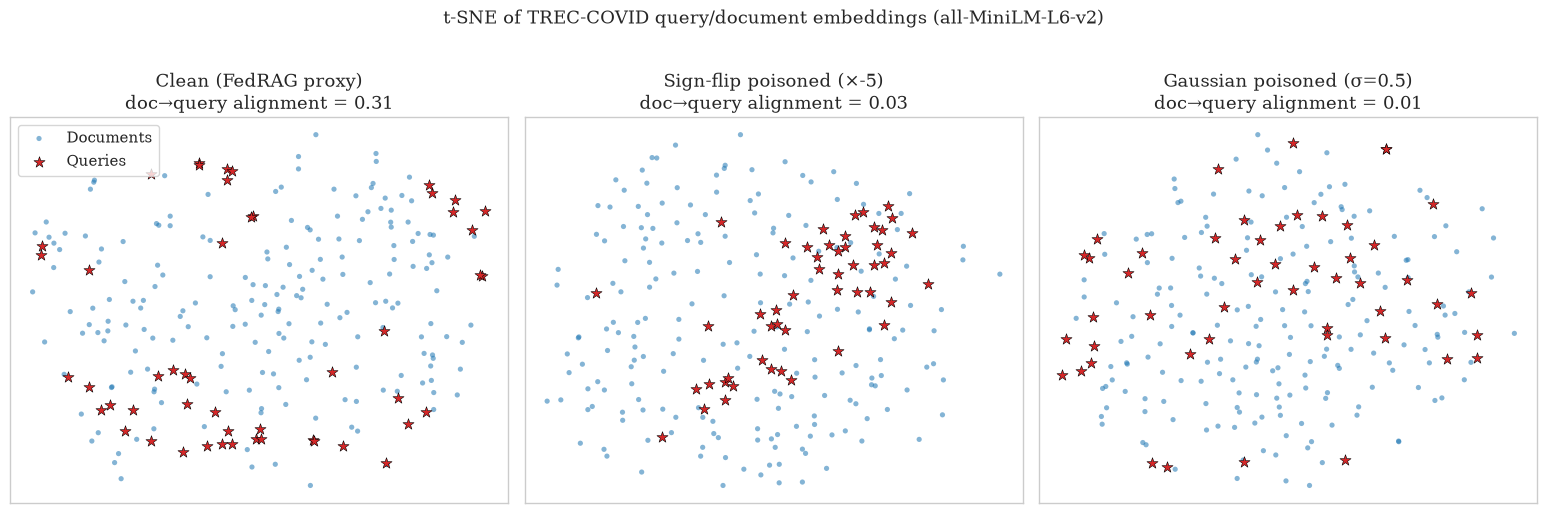

In [3]:
# ---------------- Embed, score, project ----------------
q_index = {q: i for i, q in enumerate(query_ids)}
owner_idx = np.array([q_index[q] for q in doc_owner])

def embed(model, texts):
    e = model.encode(texts, batch_size=64, convert_to_numpy=True,
                     normalize_embeddings=True, show_progress_bar=False)
    return np.nan_to_num(e, nan=0.0, posinf=0.0, neginf=0.0)

projections = {}
for name, model in models.items():
    Q, D = embed(model, query_texts), embed(model, doc_texts)
    # Quantitative companion to the picture, computed in the ORIGINAL 384-d space:
    # share of documents whose nearest query (cosine) is the query they are relevant to.
    alignment = float(np.mean((D @ Q.T).argmax(axis=1) == owner_idx))
    X = np.vstack([Q, D])
    perplexity = min(30, (len(X) - 1) // 3)
    Z = TSNE(n_components=2, perplexity=perplexity, init="pca",
             metric="cosine", random_state=SEED).fit_transform(X)
    projections[name] = (Z[:len(Q)], Z[len(Q):], alignment)
    print(f"{name:<32} doc→own-query alignment: {alignment:.3f}  (chance ≈ {1/len(Q):.3f})")

# ---------------- Plot ----------------
plt.rcParams.update({"font.family": "serif", "font.size": 11})
fig, axes = plt.subplots(1, len(projections), figsize=(5.2 * len(projections), 5), squeeze=False)
for ax, (name, (Zq, Zd, alignment)) in zip(axes[0], projections.items()):
    ax.scatter(Zd[:, 0], Zd[:, 1], s=14, c="#1f77b4", alpha=0.55, label="Documents", edgecolors="none")
    ax.scatter(Zq[:, 0], Zq[:, 1], s=70, c="#d62728", marker="*", label="Queries",
               edgecolors="black", linewidths=0.4)
    ax.set_title(f"{name}\ndoc→query alignment = {alignment:.2f}")
    ax.set_xticks([]); ax.set_yticks([])
axes[0][0].legend(loc="best", frameon=True)
fig.suptitle("t-SNE of TREC-COVID query/document embeddings (all-MiniLM-L6-v2)", y=1.02)
plt.tight_layout()
plt.savefig("fedrag_tsne_semantic_scrambling.png", dpi=300, bbox_inches="tight")
print("💾 Saved 'fedrag_tsne_semantic_scrambling.png'")
plt.show()

FedRAG runs per defense mode: {'hard': 3, 'soft': 4}
💾 Saved 'fedrag_trust_evolution.png'


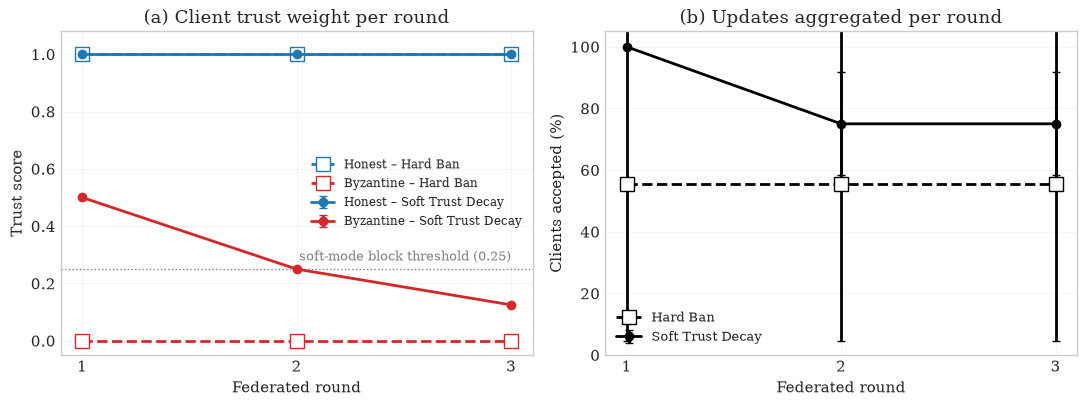

Round                     1     2      3
Defense_Mode Role                       
hard         Byzantine  0.0  0.00  0.000
             Honest     1.0  1.00  1.000
soft         Byzantine  0.5  0.25  0.125
             Honest     1.0  1.00  1.000


In [4]:
# =====================================================================
# Trust Weight Evolution + Network Participation (Soft Decay vs Hard Ban)
# =====================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

trust = pd.read_csv("trust_evolution.csv")

# Flagged_Malicious is blank on rows where a hard-banned client was skipped -> treat as not flagged that round.
trust["Flagged"] = trust["Flagged_Malicious"].astype(str).str.lower() == "true"
trust["Accepted"] = trust["Accepted"].astype(str).str.lower() == "true"

# Client IDs are random per run, so label roles from behaviour:
# a client flagged at least once in its run is the Byzantine attacker, the rest are honest.
byz = trust.groupby(["Run_ID", "Client_ID"])["Flagged"].transform("any")
trust["Role"] = np.where(byz, "Byzantine", "Honest")

n_runs = trust.groupby("Defense_Mode")["Run_ID"].nunique()
print("FedRAG runs per defense mode:", n_runs.to_dict())

# Mean ± std across runs (each run first averaged over its clients of that role)
per_run = (trust.groupby(["Defense_Mode", "Role", "Run_ID", "Round"])
                .agg(Trust=("Trust_Score", "mean"), Accepted=("Accepted", "mean"))
                .reset_index())
summary = (per_run.groupby(["Defense_Mode", "Role", "Round"])
                  .agg(Trust_mean=("Trust", "mean"), Trust_std=("Trust", "std"),
                       Acc_mean=("Accepted", "mean"), Acc_std=("Accepted", "std"))
                  .fillna(0.0).reset_index())

# Overall participation: share of ALL clients whose update was aggregated, per round
part = (trust.groupby(["Defense_Mode", "Run_ID", "Round"])["Accepted"].mean()
             .groupby(["Defense_Mode", "Round"]).agg(["mean", "std"]).fillna(0.0).reset_index())

ROLE_COLOR = {"Honest": "#1f77b4", "Byzantine": "#d62728"}
# Hard Ban drawn first with larger hollow markers so overlapping lines (e.g. honest = 1.0 in both) stay visible
MODE_STYLE = {"hard": dict(ls="--", marker="s", ms=10, mfc="white", label="Hard Ban"),
              "soft": dict(ls="-", marker="o", ms=6, mfc=None, label="Soft Trust Decay")}

plt.rcParams.update({"font.family": "serif", "font.size": 11, "lines.linewidth": 2})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) Trust evolution
for mode, style in MODE_STYLE.items():
    for role, color in ROLE_COLOR.items():
        d = summary[(summary.Defense_Mode == mode) & (summary.Role == role)]
        if d.empty:
            continue
        ax1.errorbar(d.Round, d.Trust_mean, yerr=d.Trust_std, color=color, ls=style["ls"],
                     marker=style["marker"], markersize=style["ms"], capsize=3,
                     markerfacecolor=style["mfc"] or color, label=f"{role} – {style['label']}")
ax1.axhline(0.25, color="gray", lw=1, ls=":")
ax1.text(trust.Round.max(), 0.28, "soft-mode block threshold (0.25)",
         color="gray", fontsize=9, ha="right")
ax1.set_title("(a) Client trust weight per round")
ax1.set_xlabel("Federated round"); ax1.set_ylabel("Trust score")
ax1.set_ylim(-0.05, 1.08); ax1.set_xticks(sorted(trust.Round.unique()))
ax1.legend(fontsize=8.5, loc="center right")

# (b) Network participation
for mode, style in MODE_STYLE.items():
    d = part[part.Defense_Mode == mode]
    if d.empty:
        continue
    ax2.errorbar(d.Round, 100 * d["mean"], yerr=100 * d["std"], color="black", ls=style["ls"],
                 marker=style["marker"], markersize=style["ms"], capsize=3,
                 markerfacecolor=style["mfc"] or "black", label=style["label"])
ax2.set_title("(b) Updates aggregated per round")
ax2.set_xlabel("Federated round"); ax2.set_ylabel("Clients accepted (%)")
ax2.set_ylim(0, 105); ax2.set_xticks(sorted(trust.Round.unique()))
ax2.legend(fontsize=9, loc="lower left")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fedrag_trust_evolution.png", dpi=300, bbox_inches="tight")
print("💾 Saved 'fedrag_trust_evolution.png'")
plt.show()

# Table view of the plotted numbers (handy for the paper's text)
print(summary.pivot_table(index=["Defense_Mode", "Role"], columns="Round", values="Trust_mean").round(3))